<a href="https://colab.research.google.com/github/kashish-kannojia/UCS420-KASHISHKANNOJIA/blob/main/KASHISHKANNOJIA_UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170342          # <-- your full roll number
NAME = "KASHISH KANNOJIA"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170342   Name: KASHISH KANNOJIA   Fingerprint: 38D220E0   Tickets: 14

Ticket_ID                                                                             Ticket_Text
      T01               I cannot access the projector since yesterday. I don't know what changed.
      T02                      LMS stopped responding on my laptop. It works on another computer.
      T03                      I am unable to use the student portal during the lab. Please help.
      T04                                          Re-installing didn't help; log-in still fails!
      T05                                                             Ticket #4521 is still open.
      T06                                                The VPN stopped responding. Please help.
      T07                                                   Nothing works and nobody has replied.
      T08 Printer is showing an error after resetting my password. The same problem occurs again.
      T09                     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Your code
import pandas as pd

# Use the official process_ticket() function without modifying it
tickets = df["Ticket_Text"].tolist()

processed_tickets = [
    process_ticket(ticket)
    for ticket in tickets
]

rows = []

for ticket_id, result in zip(df["Ticket_ID"], processed_tickets):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

preprocessing_df = pd.DataFrame(rows)

# Add totals for count-based columns.
# Unique-token counts are not additive, so leave that total blank.
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": preprocessing_df["Sentences"].sum(),
    "Tokens": preprocessing_df["Tokens"].sum(),
    "Punctuation Tokens": preprocessing_df["Punctuation Tokens"].sum(),
    "Stopwords": preprocessing_df["Stopwords"].sum(),
    "Unique Tokens": "-",
    "Final Tokens": preprocessing_df["Final Tokens"].sum()
}

preprocessing_df = pd.concat(
    [preprocessing_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print(preprocessing_df.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation Tokens  Stopwords Unique Tokens  Final Tokens
      T01          2      16                   2          7            14             7
      T02          2      13                   2          4            11             7
      T03          2      15                   2          6            13             7
      T04          1       9                   2          1             9             6
      T05          1       7                   2          1             7             4
      T06          2       8                   2          1             7             5
      T07          1       7                   1          2             7             4
      T08          2      16                   2          7            15             7
      T09          2      10                   2          3            10             5
      T10          2      13                   2          3            12             8
      T11          2      12    

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

NLTK's word_tokenize() separates contractions into smaller tokens, and these fragments remain because the preprocessing function does not remove them separately.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re
import pandas as pd

# Provided test lines
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Regex patterns for extraction
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",

    # Matches integers, decimals, and version numbers
    "Numbers and versions": r"(?<![\w.])(?:0[xX][0-9A-Fa-f]+|\d+(?:\.\d+)*)(?![\w.])",

    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",

    "Words beginning with a vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

# Patterns for replacement
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"

phone_pattern = (
    r"(?<!\w)(?:"
    r"\+?91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\d{4}[-.\s]\d{3}[-.\s]\d{4}"
    r")(?!\w)"
)

# Use the raw tickets generated by your official function
raw_tickets = df["Ticket_Text"].tolist()

# Combine raw tickets and test lines
all_texts = raw_tickets + TEST_LINES

# Extraction using re.findall()
for category, pattern in patterns.items():
    print("\n" + "=" * 60)
    print(category)
    print("=" * 60)

    for i, text in enumerate(all_texts, start=1):
        matches = re.findall(pattern, text)
        if matches:
            print(f"Text {i}: {matches}")

# Replace sensitive information using re.sub()
def replace_sensitive_info(text):
    # Replace URLs first to avoid matching phone-like strings inside URLs
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\n" + "=" * 60)
print("EMAIL, URL AND PHONE NUMBER REPLACEMENT")
print("=" * 60)

for i, text in enumerate(all_texts, start=1):
    print(f"\nOriginal {i}:  {text}")
    print(f"Modified {i}:  {replace_sensitive_info(text)}")


Words longer than 5 letters
Text 1: ['cannot', 'access', 'projector', 'yesterday', 'changed']
Text 2: ['stopped', 'responding', 'laptop', 'another', 'computer']
Text 3: ['unable', 'student', 'portal', 'during', 'Please']
Text 4: ['installing']
Text 5: ['Ticket']
Text 6: ['stopped', 'responding', 'Please']
Text 7: ['Nothing', 'nobody', 'replied']
Text 8: ['Printer', 'showing', 'resetting', 'password', 'problem', 'occurs']
Text 9: ['disconnecting', 'another', 'solution']
Text 10: ['failed', 'yesterday', 'another', 'computer']
Text 11: ['Printer', 'disconnecting', 'mobile', 'hotspot', 'Please']
Text 12: ['Version', 'crashes']
Text 13: ['working', 'before', 'assignment', 'deadline', 'Please']
Text 14: ['stopped', 'syncing', 'uploading', 'worked', 'yesterday']
Text 15: ['helpdesk', 'thapar', 'thapar', 'thapar']
Text 16: ['Version']

Numbers and versions
Text 5: ['4521']
Text 12: ['2.0.1', '99']
Text 16: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']
T

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

Some of the capitalized words are capitalized only because they appear at the beginning of a sentence, such as Mail, Call, and The in the provided TEST_LINES. Other capitalized words may be proper nouns or technical terms, such as Version. The exact number can be found by checking which capitalized words occur at the start of sentences and are not normally capitalized

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code


import re
from nltk.tokenize import RegexpTokenizer, word_tokenize
import pandas as pd

# One pattern that preserves URLs, emails, phone numbers,
# versions, decimals, hyphenated words and contractions
pattern = (
    r"https?://[^\s<>]+|www\.[^\s<>]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+?91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\d{4}[-.\s]\d{3}[-.\s]\d{4}"
    r"|\d+(?:\.\d+)+|\d+"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+(?:'[A-Za-z]+)+"
    r"|[A-Za-z]+"
    r"|[^\w\s]"
)

# Create the custom tokenizer
custom_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

# Test on TEST_LINES and raw tickets
all_texts = df["Ticket_Text"].tolist() + TEST_LINES

rows = []

for i, text in enumerate(all_texts, start=1):
    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    rows.append({
        "Text_ID": i,
        "Original_Text": text,
        "Custom_Tokens": custom_tokens,
        "NLTK_Tokens": nltk_tokens
    })

comparison_df = pd.DataFrame(rows)

# Display the comparison
pd.set_option("display.max_colwidth", None)
display(comparison_df)

# Show the required examples of differences
print("\n--- Examples of tokenizer differences ---")

for text in TEST_LINES:
    print("\nOriginal:", text)
    print("Custom:  ", my_tokenize(text))
    print("NLTK:    ", word_tokenize(text))


,Text_ID,Original_Text,Custom_Tokens,NLTK_Tokens
0,1,I cannot access the projector since yesterday. I don't know what changed.,"[I, cannot, access, the, projector, since, yesterday, ., I, don't, know, what, changed, .]","[I, can, not, access, the, projector, since, yesterday, ., I, do, n't, know, what, changed, .]"
1,2,LMS stopped responding on my laptop. It works on another computer.,"[LMS, stopped, responding, on, my, laptop, ., It, works, on, another, computer, .]","[LMS, stopped, responding, on, my, laptop, ., It, works, on, another, computer, .]"
2,3,I am unable to use the student portal during the lab. Please help.,"[I, am, unable, to, use, the, student, portal, during, the, lab, ., Please, help, .]","[I, am, unable, to, use, the, student, portal, during, the, lab, ., Please, help, .]"
3,4,Re-installing didn't help; log-in still fails!,"[Re-installing, didn't, help, ;, log-in, still, fails, !]","[Re-installing, did, n't, help, ;, log-in, still, fails, !]"
4,5,Ticket #4521 is still open.,"[Ticket, #, 4521, is, still, open, .]","[Ticket, #, 4521, is, still, open, .]"
5,6,The VPN stopped responding. Please help.,"[The, VPN, stopped, responding, ., Please, help, .]","[The, VPN, stopped, responding, ., Please, help, .]"
6,7,Nothing works and nobody has replied.,"[Nothing, works, and, nobody, has, replied, .]","[Nothing, works, and, nobody, has, replied, .]"
7,8,Printer is showing an error after resetting my password. The same problem occurs again.,"[Printer, is, showing, an, error, after, resetting, my, password, ., The, same, problem, occurs, again, .]","[Printer, is, showing, an, error, after, resetting, my, password, ., The, same, problem, occurs, again, .]"
8,9,The Wi-Fi keeps disconnecting. Is there another solution?,"[The, Wi-Fi, keeps, disconnecting, ., Is, there, another, solution, ?]","[The, Wi-Fi, keeps, disconnecting, ., Is, there, another, solution, ?]"
9,10,VPN failed to open since yesterday. It works on another computer.,"[VPN, failed, to, open, since, yesterday, ., It, works, on, another, computer, .]","[VPN, failed, to, open, since, yesterday, ., It, works, on, another, computer, .]"



--- Examples of tokenizer differences ---

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:     ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom:   ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK:     ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't open; 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

The custom tokenizer `my_tokenize(text)` uses a single regular-expression pattern to preserve contractions, hyphenated words, decimals, version numbers, email addresses, URLs, and phone numbers as single tokens.

Compared with NLTK's `word_tokenize()`, the custom tokenizer can produce different results. First, it keeps contractions such as `isn't` together, whereas NLTK may split them into `is` and `n't`. Second, it preserves complete email addresses such as `it.helpdesk@thapar.edu` as one token instead of splitting them into smaller parts. Third, it explicitly keeps decimal numbers such as `95.5` and software versions such as `2.0.1` together. These differences show that a custom tokenizer can be designed to preserve specific structures that are important for IT support tickets.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your Code

import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# Download resources if needed
nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Get unique alphabetic final tokens from the official preprocessing pipeline
unique_final_tokens = sorted({
    token.lower()
    for result in processed_tickets
    for token in result["final"]
    if token.isalpha()
})

# Initialize the four methods
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

# Select a suffix based on words in the dataset
suffix = "ing"

matching_words = [
    word for word in unique_final_tokens
    if word.endswith(suffix) and len(word) > len(suffix)
]

print("Words in the dataset ending with 'ing':", matching_words)
print("Number of matching words:", len(matching_words))

# Use the suffix only if at least two dataset words support the choice
if len(matching_words) < 2:
    raise ValueError(
        "Fewer than two words end with 'ing'. Choose another suffix "
        "that occurs in at least two unique final tokens."
    )

regexp_stemmer = RegexpStemmer(suffix, min=4)

# Convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"  # adjective
    elif tag.startswith("V"):
        return "v"  # verb
    elif tag.startswith("N"):
        return "n"  # noun
    elif tag.startswith("R"):
        return "r"  # adverb
    return "n"

# Assign POS information to the unique tokens
tagged_words = nltk.pos_tag(unique_final_tokens)

rows = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    # Include only words for which at least two outputs differ
    outputs = {
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    }

    if len(outputs) > 1:
        rows.append({
            "Word": word,
            "POS": tag,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regexp_result,
            "WordNet Lemma": lemma_result
        })

comparison_df = pd.DataFrame(rows)

print("\nWords where the four methods do not all agree:")
display(comparison_df)


Words in the dataset ending with 'ing': ['disconnecting', 'nothing', 'resetting', 'responding', 'showing', 'syncing', 'uploading', 'working']
Number of matching words: 8

Words where the four methods do not all agree:


,Word,POS,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,changed,VBD,chang,chang,changed,change
3,computer,NN,comput,comput,computer,computer
4,crashes,NNS,crash,crash,crashes,crash
5,deadline,VBP,deadlin,deadlin,deadline,deadline
6,error,NN,error,er,error,error
7,failed,VBD,fail,fail,failed,fail
8,fails,NNS,fail,fail,fails,fails
9,file,VB,file,fil,file,file


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

Over-stemming: The Lancaster Stemmer converts solution → solv, which removes too much of the original word and produces an unclear stem.



Under-stemming: The Regexp Stemmer leaves changed → changed, while the WordNet Lemmatizer converts it to change. The Regexp Stemmer does not reduce this word because it only removes the specified suffix ing.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus Statistics:


,Total Tokens,Unique Tokens,TTR
S1: All Tokens,158.0,90.0,0.5696
S2: No Punctuation,131.0,84.0,0.6412
S3: Final Tokens,85.0,59.0,0.6941
S4: Porter Stemmed,85.0,56.0,0.6588



Top 10 words in S1 (All Tokens):
     Word  Frequency
        .         22
      the          8
     help          5
        i          4
   please          4
       is          4
yesterday          3
  stopped          3
       on          3
       it          3

Top 10 words in S3 (Final Tokens):
      Word  Frequency
      help          5
    please          4
 yesterday          3
   stopped          3
     works          3
   another          3
     since          2
       n't          2
responding          2
  computer          2


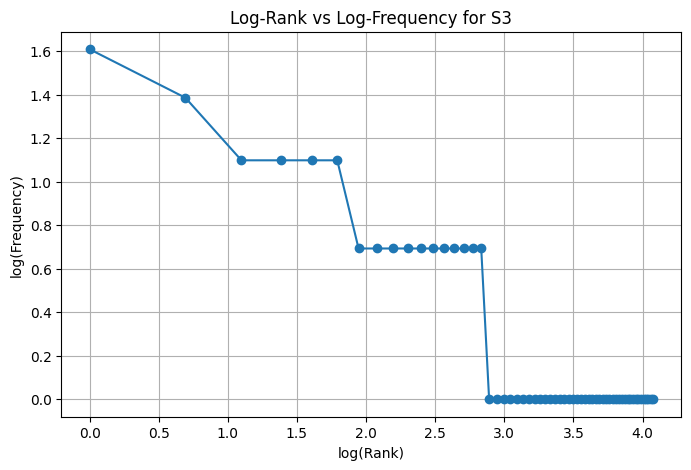


Top 5 bigrams in S1:
     Bigram  Frequency
   . please          4
please help          4
     help .          4
yesterday .          3
       . it          3

Top 5 bigrams in S3:
            Bigram  Frequency
       please help          4
   since yesterday          2
stopped responding          2
     works another          2
  another computer          2


In [ ]:
# Your code

import string
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

# S1: All tokens, including punctuation
S1 = [
    token
    for result in processed_tickets
    for token in result["tokens"]
]

# S2: Tokens without punctuation
S2 = [
    token for token in S1
    if not all(ch in string.punctuation for ch in token)
]

# S3: Final tokens after removing punctuation and stopwords
S3 = [
    token
    for result in processed_tickets
    for token in result["final"]
]

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

# Calculate corpus statistics
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame({
    "S1: All Tokens": corpus_stats(S1),
    "S2: No Punctuation": corpus_stats(S2),
    "S3: Final Tokens": corpus_stats(S3),
    "S4: Porter Stemmed": corpus_stats(S4)
}).T

print("Corpus Statistics:")
display(stats)

# 1. Top 10 words in S1 and S3
print("\nTop 10 words in S1 (All Tokens):")
print(pd.DataFrame(Counter(S1).most_common(10),
                   columns=["Word", "Frequency"]).to_string(index=False))

print("\nTop 10 words in S3 (Final Tokens):")
print(pd.DataFrame(Counter(S3).most_common(10),
                   columns=["Word", "Frequency"]).to_string(index=False))

# 2. Plot log(rank) vs log(frequency) for S3
frequency_counts = sorted(Counter(S3).values(), reverse=True)
ranks = list(range(1, len(frequency_counts) + 1))

log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(freq) for freq in frequency_counts]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.show()

# 3. Top 5 bigrams in S1 and S3
# Count bigrams within each ticket so they do not cross ticket boundaries.
bigrams_S1 = Counter()
bigrams_S3 = Counter()

for result in processed_tickets:
    bigrams_S1.update(ngrams(result["tokens"], 2))
    bigrams_S3.update(ngrams(result["final"], 2))

print("\nTop 5 bigrams in S1:")
print(pd.DataFrame(
    [(f"{a} {b}", count) for (a, b), count in bigrams_S1.most_common(5)],
    columns=["Bigram", "Frequency"]
).to_string(index=False))

print("\nTop 5 bigrams in S3:")
print(pd.DataFrame(
    [(f"{a} {b}", count) for (a, b), count in bigrams_S3.most_common(5)],
    columns=["Bigram", "Frequency"]
).to_string(index=False))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

TTR changes because punctuation and stopwords are removed, and Porter stemming converts related words into common stems. Removing punctuation and stopwords can increase or decrease TTR, while stemming usually reduces the number of unique tokens by combining related word forms.

In [ ]:
# QUESTION-6

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

For example, isn't may be split into is and n't by NLTK's word_tokenize(), whereas my custom tokenizer keeps isn't as one token. This happens because my regular expression is designed to preserve contractions.

(c) Give one example where stemming produces an undesirable result.

The Lancaster Stemmer converts solution into solv. This is undesirable because the resulting stem is not a complete, meaningful word and loses the original word's clarity.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

For the word changed, the Porter Stemmer produces chang, whereas the WordNet Lemmatizer produces change. The lemma is a meaningful dictionary word that preserves the intended meaning more clearly than the stem.